# Qualidade dos dados nas duas janelas

V0 original; V1 sem fins de semana; V2 sem suspeitos. Experimento de 04/10/2026 para decidir a revisão da preparação. Mantém consumos baixos na avaliação, estimadores e regras de margem. Não modifica previsões emitidas, dados originais ou dissertações. 2026 é diagnóstico exploratório.

In [1]:
from pathlib import Path
import json, os, subprocess, sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path(r'F:\PRODUTO_MESTRADO')
OUT = ROOT / 'resultados/qualidade_calendario_consumo/experimento_20261004'
result = subprocess.run([sys.executable, str(ROOT/'scripts/testar_qualidade_dados_duas_janelas.py')],
    capture_output=True, text=True, encoding='utf-8', env=dict(os.environ, PYTHONIOENCODING='utf-8', PYTHONDONTWRITEBYTECODE='1'))
assert result.returncode == 0, result.stderr
print(result.stdout.splitlines()[0])
def read(name): return pd.read_csv(OUT/name)


Resultados preservados e conferidos por hash.


## Triagem e contagens

Ausência não é zero. Suspeita não confirma erro. Os limiares foram fixados antes da nova medição.

In [2]:
display(read('contagens_gold_por_ano.csv'))
triagem=read('registro_triagem.csv')
display(triagem.loc[triagem.consumo_total.notna() & (triagem.suspeito|triagem.fim_de_semana),
    ['data','consumo_total','reservas','status_legal','motivo_v2']])


,ano,observacoes_originais,fins_de_semana,suspeitos_dias_uteis,restantes_V1,restantes_V2
0,2023,181,0,6,181,175
1,2024,149,3,4,146,142
2,2025,173,0,4,173,169
3,2026,123,0,3,123,120


,data,consumo_total,reservas,status_legal,motivo_v2
94,2023-07-03,16.0,50.0,letivo,baixo_vs_historico
95,2023-07-04,7.0,28.0,letivo,baixo_vs_reserva|baixo_vs_historico
96,2023-07-05,1.0,18.0,letivo,baixo_vs_reserva|baixo_vs_historico
98,2023-07-28,24.0,46.0,letivo,baixo_vs_historico
171,2023-11-28,8.0,94.0,letivo,baixo_vs_reserva|baixo_vs_historico
180,2023-12-11,5.0,37.0,letivo,baixo_vs_reserva|baixo_vs_historico
211,2024-03-28,143.0,108.0,nao_letivo,consumo_em_dia_nao_letivo|reserva_em_dia_nao_l...
212,2024-03-29,183.0,NaN,nao_letivo,consumo_em_dia_nao_letivo
213,2024-04-01,187.0,175.0,nao_letivo,consumo_em_dia_nao_letivo|reserva_em_dia_nao_l...
217,2024-04-12,104.0,NaN,nao_letivo,consumo_em_dia_nao_letivo


## Comparação pareada

As mesmas refeições e os casos de consumo baixo permanecem no confronto principal. O quantitativo institucional é a referência; margens protegem contra déficit, com possível excesso.

In [3]:
scores=read('metricas_principal_calendario.csv')
display(scores.loc[scores.ano.isin([2025,2026]), ['ano','versao','metodo','n_datas','MAE_refeicoes',
    'excesso_potencial','deficit_potencial','dias_deficit','perda_2a1']].round(2))
display(read('diferencas_pareadas_MAE.csv').query('ano in [2025,2026]').round(2))


,ano,versao,metodo,n_datas,MAE_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_2a1
2,2025,V0 original,Referência sazonal compras,153,19.48,1668.0,1313.0,68,28.07
3,2026,V0 original,Referência sazonal compras,123,41.95,1859.0,3301.0,81,68.79
10,2025,V0 original,Compras pura,153,23.60,2452.0,1159.0,62,31.18
11,2025,V0 original,Compras moderada,153,27.04,3480.0,657.0,39,31.33
12,2025,V0 original,Compras conservadora,153,61.99,9452.0,33.0,2,62.21
...,...,...,...,...,...,...,...,...,...
127,2026,V2 sem suspeitos,Preparo pura,123,35.84,1393.0,3015.0,87,60.35
128,2026,V2 sem suspeitos,Preparo moderada,123,32.39,1796.0,2188.0,76,50.18
129,2026,V2 sem suspeitos,Preparo conservadora,123,32.59,3081.0,928.0,44,40.14
130,2026,V2 sem suspeitos,Preparo combinado +10,123,24.99,2686.0,388.0,33,28.15


,ano,metodo,nova_versao,referencia,n_datas,delta_MAE,IC95_inferior,IC95_superior,interpretacao
22,2025,Preparo pura,V1 sem fins de semana,V0 original,153,0.05,-0.20,0.31,Descritivo exploratório; negativo favorece a n...
23,2025,Preparo pura,V2 sem suspeitos,V1 sem fins de semana,153,0.24,-0.40,0.95,Descritivo exploratório; negativo favorece a n...
24,2025,Preparo moderada,V1 sem fins de semana,V0 original,153,0.05,-0.21,0.32,Descritivo exploratório; negativo favorece a n...
25,2025,Preparo moderada,V2 sem suspeitos,V1 sem fins de semana,153,0.40,-0.17,1.00,Descritivo exploratório; negativo favorece a n...
26,2025,Preparo conservadora,V1 sem fins de semana,V0 original,153,0.29,-0.06,0.68,Descritivo exploratório; negativo favorece a n...
27,2025,Preparo conservadora,V2 sem suspeitos,V1 sem fins de semana,153,-7.07,-7.96,-6.11,Descritivo exploratório; negativo favorece a n...
28,2025,Preparo com reserva pura,V1 sem fins de semana,V0 original,153,0.09,-0.16,0.34,Descritivo exploratório; negativo favorece a n...
29,2025,Preparo com reserva pura,V2 sem suspeitos,V1 sem fins de semana,153,0.20,-0.51,1.03,Descritivo exploratório; negativo favorece a n...
30,2025,Preparo com reserva +10,V1 sem fins de semana,V0 original,153,0.12,-0.14,0.41,Descritivo exploratório; negativo favorece a n...
31,2025,Preparo com reserva +10,V2 sem suspeitos,V1 sem fins de semana,153,0.59,-0.09,1.46,Descritivo exploratório; negativo favorece a n...


## Sensibilidade aos suspeitos

A análise separada ajuda a detectar o prejuízo de retirar um evento raro verdadeiro do histórico. Não é autorização para retirar essas refeições da pontuação principal.

In [4]:
for name in ['sensibilidade_suspeitos','sensibilidade_sem_suspeitos','diagnostico_todas_datas']:
    print(name)
    display(read('metricas_'+name+'.csv').query('ano in [2025,2026]')
        [['ano','versao','metodo','n_datas','MAE_refeicoes']].round(2))


sensibilidade_suspeitos


,ano,versao,metodo,n_datas,MAE_refeicoes
1,2026,V0 original,Referência sazonal compras,3,156.33
5,2026,V0 original,Compras pura,3,137.33
6,2026,V0 original,Compras moderada,3,147.33
7,2026,V0 original,Compras conservadora,3,182.67
10,2026,V0 original,Preparo com reserva pura,3,123.33
11,2026,V0 original,Preparo com reserva +10,3,133.33
17,2026,V0 original,Preparo pura,3,124.33
18,2026,V0 original,Preparo moderada,3,134.33
19,2026,V0 original,Preparo conservadora,3,161.33
20,2026,V0 original,Preparo combinado +10,3,129.67


sensibilidade_sem_suspeitos


,ano,versao,metodo,n_datas,MAE_refeicoes
2,2025,V0 original,Referência sazonal compras,153,19.48
3,2026,V0 original,Referência sazonal compras,120,39.09
10,2025,V0 original,Compras pura,153,23.60
11,2025,V0 original,Compras moderada,153,27.04
12,2025,V0 original,Compras conservadora,153,61.99
...,...,...,...,...,...
127,2026,V2 sem suspeitos,Preparo pura,120,33.54
128,2026,V2 sem suspeitos,Preparo moderada,120,29.76
129,2026,V2 sem suspeitos,Preparo conservadora,120,29.46
130,2026,V2 sem suspeitos,Preparo combinado +10,120,22.35


diagnostico_todas_datas


,ano,versao,metodo,n_datas,MAE_refeicoes
2,2025,V0 original,Referência sazonal compras,155,20.04
3,2026,V0 original,Referência sazonal compras,123,41.95
10,2025,V0 original,Compras pura,155,24.01
11,2025,V0 original,Compras moderada,155,27.40
12,2025,V0 original,Compras conservadora,155,62.04
...,...,...,...,...,...
127,2026,V2 sem suspeitos,Preparo pura,123,35.84
128,2026,V2 sem suspeitos,Preparo moderada,123,32.39
129,2026,V2 sem suspeitos,Preparo conservadora,123,32.59
130,2026,V2 sem suspeitos,Preparo combinado +10,123,24.99


## Representações dos resultados

MAE em refeições por dia, nas mesmas datas. Legendas e rótulos em português; títulos e interpretações ficam no texto.

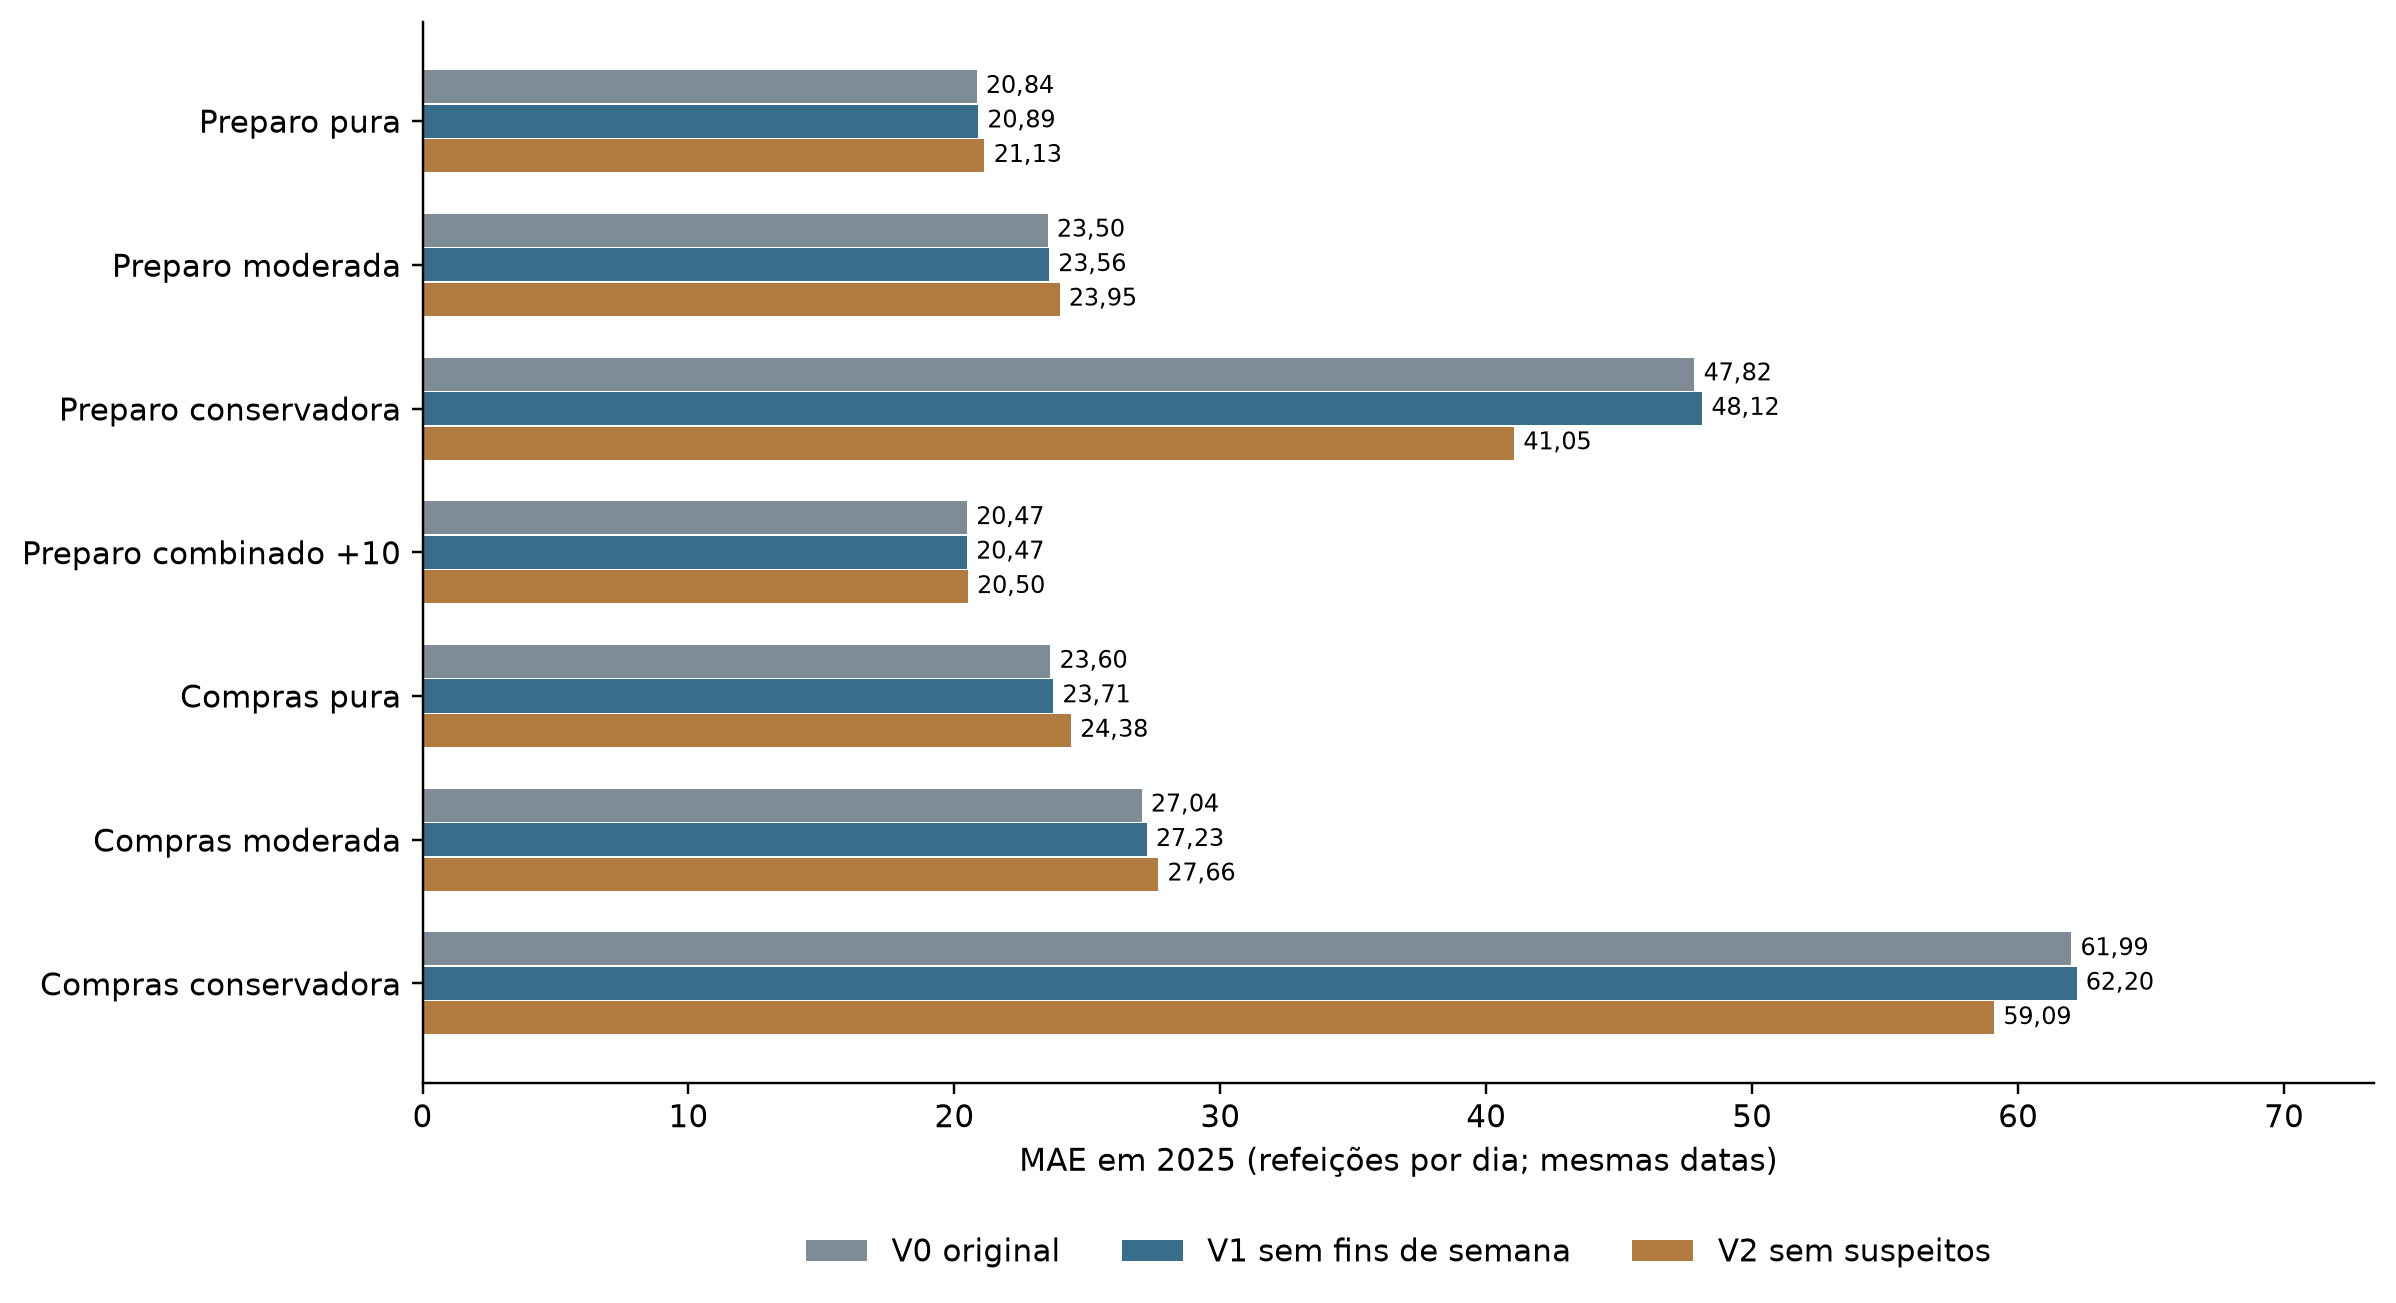

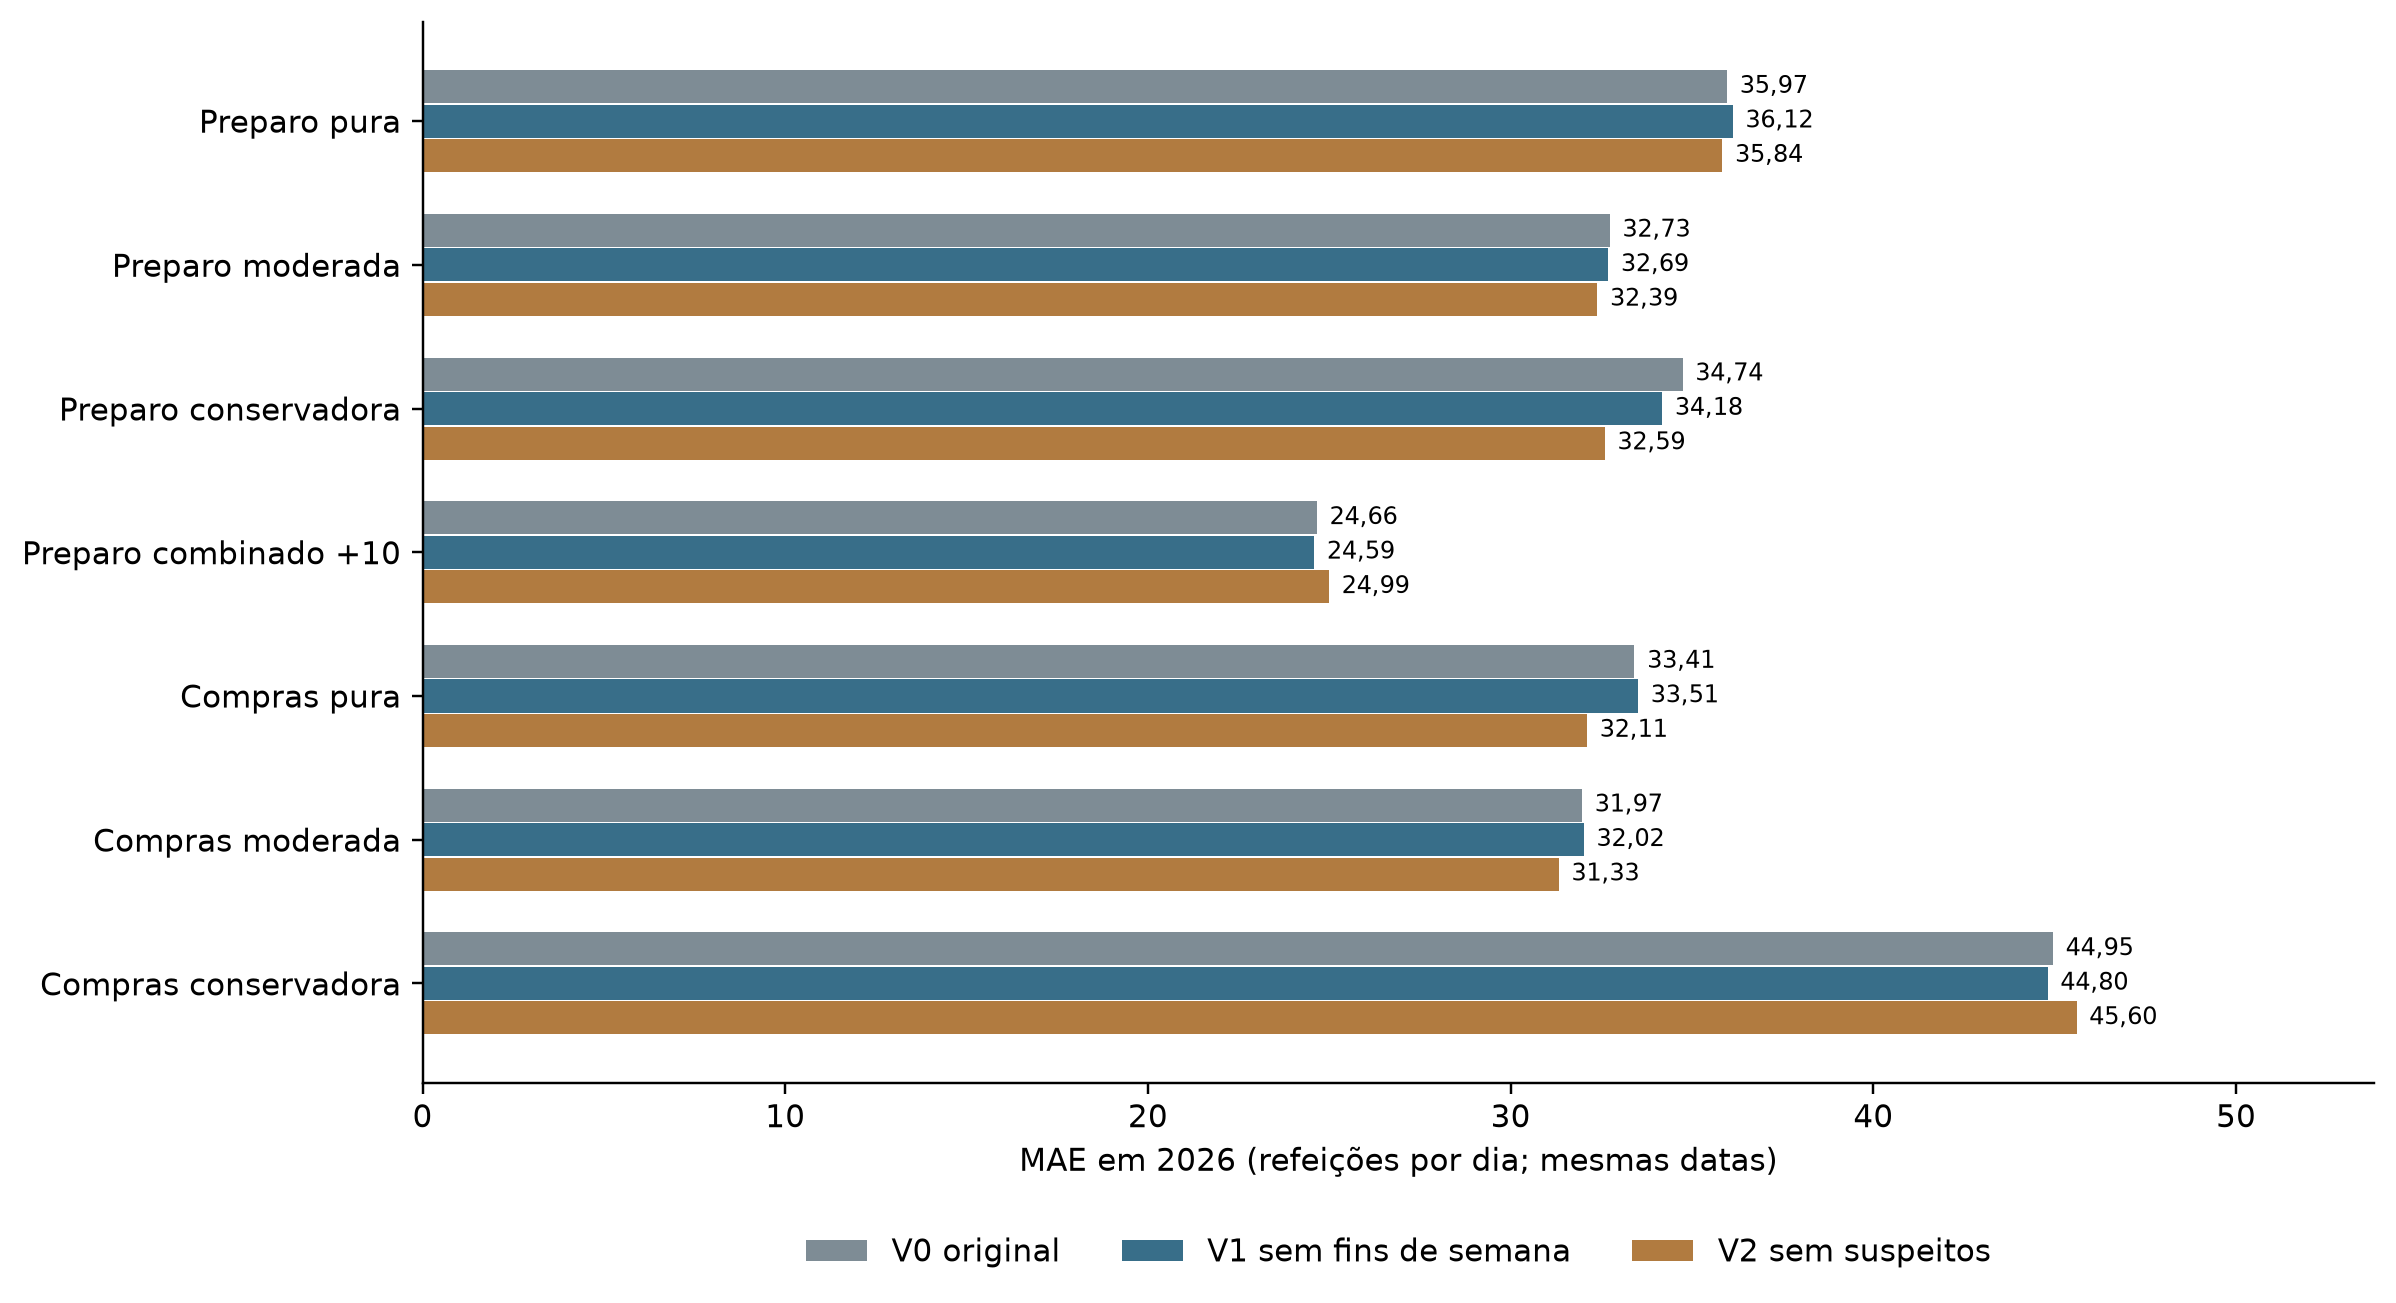

In [5]:
for year in [2025,2026]: display(Image(filename=str(OUT/f'figuras/qualidade_MAE_{year}.png')))


## Filtro diário e emissão experimental

Cada dia é selecionado separadamente. Recesso em 12–16/10 não gera previsão; emissão de compras para 19–23/10 só em 09/10. As novas saídas são experimentais; a antecedência real da emissão de domingo é 1–5 dias.

In [6]:
emission=json.loads((OUT/'emissao_experimental.json').read_text(encoding='utf-8'))
display(pd.read_csv(Path(emission['pasta'])/'previsoes_experimentais_congeladas.csv'))
display(read('agenda_filtro_diario_outubro.csv'))


,data,versao,janela,emitido_em,origem_informacao,antecedencia_nominal_dias,antecedencia_real_dias,previsao_continua,plano_puro,plano_moderado,plano_conservador,quantitativo_institucional,plano_combinado_mais10,ultima_data_consumo_disponivel,ultima_data_residuo,consumo_observado
0,2026-10-05,V1 sem fins de semana,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,3,1,177.415913,178,188,215,225,224,2026-08-31,2025-12-16,NaN
1,2026-10-06,V1 sem fins de semana,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,4,2,166.730761,167,177,204,220,217,2026-08-31,2025-12-16,NaN
2,2026-10-07,V1 sem fins de semana,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,5,3,168.858098,169,179,207,220,218,2026-08-31,2025-12-16,NaN
3,2026-10-08,V1 sem fins de semana,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,6,4,160.635402,161,171,198,210,208,2026-08-31,2025-12-16,NaN
4,2026-10-09,V1 sem fins de semana,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,7,5,166.561624,167,177,204,200,202,2026-08-31,2025-12-16,NaN
5,2026-10-05,V2 sem suspeitos,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,3,1,164.056268,165,175,195,225,220,2026-08-31,2025-12-11,NaN
6,2026-10-06,V2 sem suspeitos,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,4,2,153.439646,154,164,185,220,214,2026-08-31,2025-12-11,NaN
7,2026-10-07,V2 sem suspeitos,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,5,3,158.984244,159,169,190,220,215,2026-08-31,2025-12-11,NaN
8,2026-10-08,V2 sem suspeitos,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,6,4,150.415439,151,161,182,210,206,2026-08-31,2025-12-11,NaN
9,2026-10-09,V2 sem suspeitos,Preparo,2026-10-04T00:47:36.405824-03:00,2026-10-02,7,5,153.073898,154,164,184,200,199,2026-08-31,2025-12-11,NaN


,data,elegivel_emissao,motivo_exclusao_emissao,janela,origem_planejada,emissao_futura_ja_realizada
0,2026-10-05,True,NaN,Preparo,2026-10-02,False
1,2026-10-06,True,NaN,Preparo,2026-10-02,False
2,2026-10-07,True,NaN,Preparo,2026-10-02,False
3,2026-10-08,True,NaN,Preparo,2026-10-02,False
4,2026-10-09,True,NaN,Preparo,2026-10-02,False
5,2026-10-12,False,dia_nao_letivo|feriado,Compras,2026-10-02,False
6,2026-10-13,False,dia_nao_letivo|ferias_ou_recesso,Compras,2026-10-02,False
7,2026-10-14,False,dia_nao_letivo|ferias_ou_recesso,Compras,2026-10-02,False
8,2026-10-15,False,dia_nao_letivo|ferias_ou_recesso,Compras,2026-10-02,False
9,2026-10-16,False,dia_nao_letivo|ferias_ou_recesso,Compras,2026-10-02,False


## Decisão e auditoria

O critério foi registrado para 2025: V2 não pode piorar o MAE puro nem a perda 2:1 moderada nas duas janelas. O resultado de 2026 não seleciona a exclusão. Ler o relatório antes de adotar uma preparação.

In [7]:
display(json.loads((OUT/'decisao.json').read_text(encoding='utf-8')))
display(json.loads((OUT/'auditoria_final.json').read_text(encoding='utf-8')))
origins=read('auditoria_origens.csv')
assert origins.invariancia_triagem_futura.all() and origins.invariancia_atributos_futuros.all()
print('Origens auditadas:',len(origins))
print('Relatório:',OUT/'RELATORIO_EXPERIMENTO_QUALIDADE.md')


{'criterios_2025': [{'janela': 'Preparo',
   'MAE_V2_nao_piora_2025': False,
   'perda_2a1_moderada_V2_nao_piora_2025': False},
  {'janela': 'Compras',
   'MAE_V2_nao_piora_2025': False,
   'perda_2a1_moderada_V2_nao_piora_2025': False}],
 'V2_candidato': False,
 'adocao_operacional_realizada': False,
 'conclusao': 'Avaliar com consumo baixo real mantido na coorte principal; hipótese de qualidade não confirma erro.'}

{'concluida': True,
 'grupos_metricas_recalculados': 132,
 'reproducao_controle': [{'controle': 'Independente',
   'n_datas': 562,
   'maior_diferenca_continua': 0.0},
  {'controle': 'Com quantitativo',
   'n_datas': 520,
   'maior_diferenca_continua': 0.0},
  {'controle': 'Ridge residual',
   'n_datas': 547,
   'maior_diferenca_continua': 0.0}],
 'teste_semanas_parciais': [{'cenario_sintetico': 'Sexta feriado',
   'dias_elegiveis': [0, 1, 2, 3],
   'resultado': True},
  {'cenario_sintetico': 'Segunda facultativa e terça feriado',
   'dias_elegiveis': [2, 3, 4],
   'resultado': True},
  {'cenario_sintetico': 'Também sexta cancelada',
   'dias_elegiveis': [2, 3],
   'resultado': True}],
 'fontes_dissertacoes_e_emissoes_preservadas': True,
 'arquivos_checkpoint_preservados': 62,
 'calendario_integral_preservado_consumo_fim_de_semana_removido': True,
 'servico_realizado_nao_preditor': True,
 'exclusao_suspeitos_nao_equivale_correcao_confirmada': True,
 'ausencia_distinta_de_zero_testada':

Origens auditadas: 789
Relatório: F:\PRODUTO_MESTRADO\resultados\qualidade_calendario_consumo\experimento_20261004\RELATORIO_EXPERIMENTO_QUALIDADE.md


Próximo passo: verificar fontes dos registros suspeitos e manter o confronto prospectivo. Não houve retreino com alvos de 2026, reajuste de pesos, atualização da dissertação ou publicação no GitHub nesta etapa.